# **Customer Data Analysis**

# **Problem Statements -**

1.	How is the shopping distribution according to gender?
2.	Which gender did we sell more products to?
3.	Which gender generated more revenue?
4.	Distribution of purchase categories relative to other columns?
5.	How is the shopping distribution according to age?
6.	Which age cat did we sell more products to?
7.	Which age cat generated more revenue?
8.	Does the payment method have a relation with other columns?
9.	How is the distribution of the payment method?


## **Shoppong Mall**

![Shopping mall](mall.png)
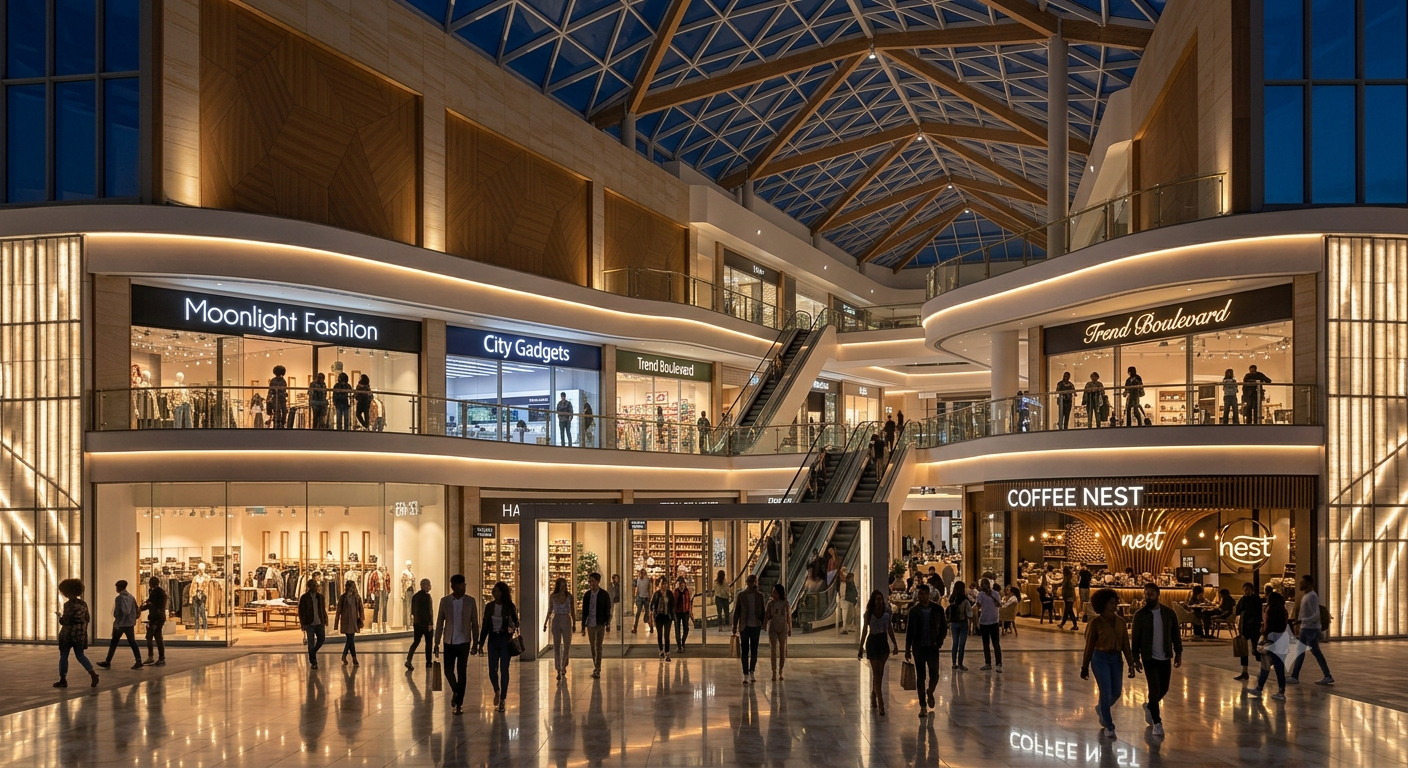
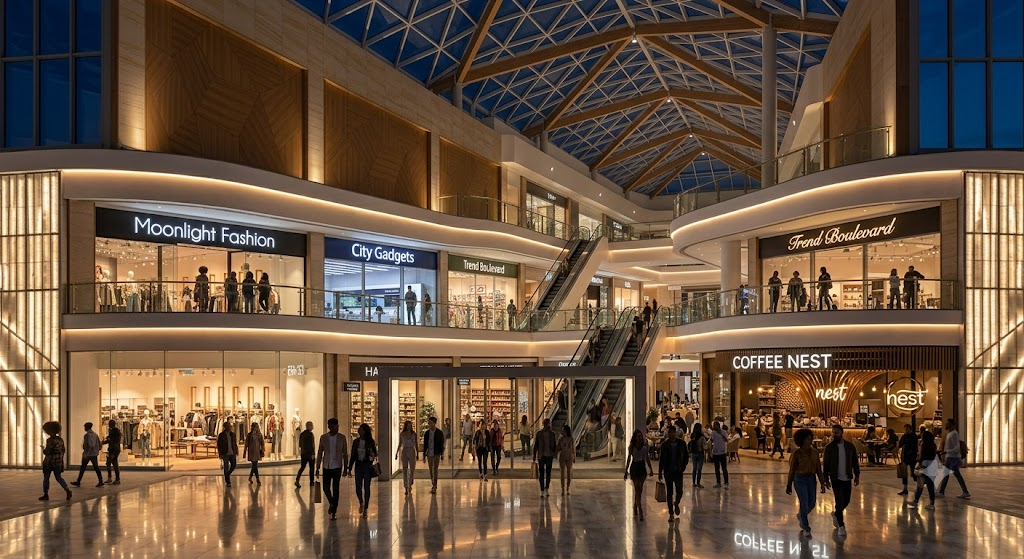
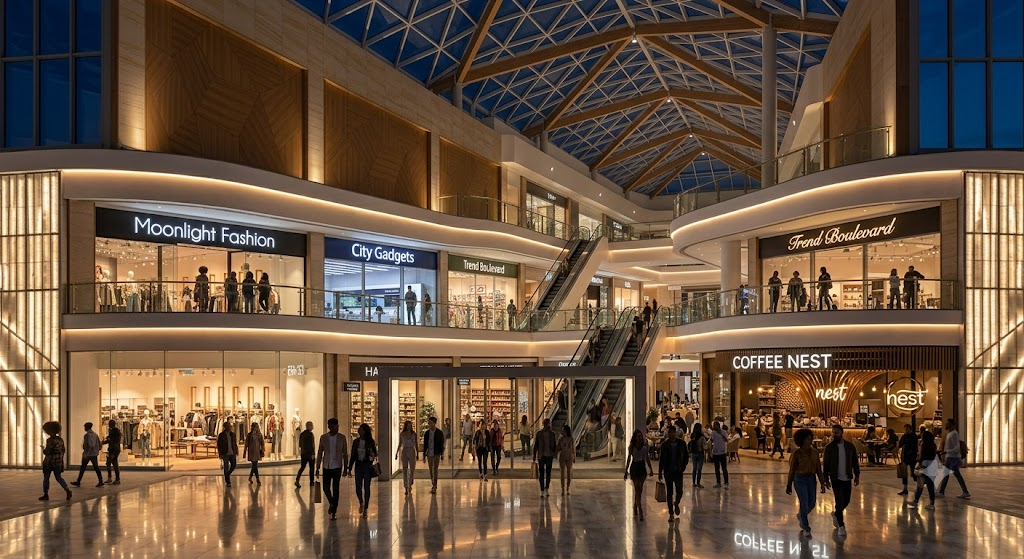

# **Importing the necessary libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt     #for visualization
import seaborn as sns               #for visualisation
import warnings
warnings.filterwarnings('ignore')

# **Load Customer Dataset**

In [2]:
# importing the dataset
customer_df = pd.read_csv(r"C:\Users\Ramchandra Wadkar\OneDrive\Documents\Data_Science\CDS\Project\Capstone Projects\Customer Data Analysis (PRDA-05)\Customer.csv")
customer_df

#### **About the Dataset**

*   This customer data analysis dataset contains 1000 observations from Istanbul, with 10 columns (Shape: 1000,10).

*   The dataset contains shopping information from 10 different shopping malls between 2021 and 2023. This data is from various age groups and genders to provide a comprehensive view of shopping habits in Istanbul.

*   The data includes both categorical and numeric values, providing information about shopping behaviours.


#### **UNDERSTAND THE GIVEN VARIABLES**

*   invoice_no: A combination of the letter 'I' and a 6-digit integer uniquely assigned to each operation.
  
*   customer_id: A combination of the letter 'C' and a 6-digit integer uniquely assigned to each operation.

*   gender: String variable of the customer's gender.

*   age: Positive Integer variable of the customers age.

*   category: String variable of the category of the purchased product.

*   quantity: The quantities of each product (item) per transaction.

*   price: Product price per unit in Turkish Liras (TL).

*   payment_method: String variable of the payment method (cash, credit card or debit card) used for the transaction.

*   invoice_date: The day when a transaction was generated.

*   shopping_mall: String variable of the name of the shopping mall where the transaction was made.



# **Data Cleaning**

In [3]:
# Checking columns names
customer_df.columns # No works in column-rename needed

In [4]:
# Size/Shape
customer_df.shape

In [5]:
# Columns info
customer_df.info()

In [6]:
# Checking each columns for Inconsistent formatting or spelling errors

# customer_df['invoice_no'].unique()
# ...
# ...
customer_df['quantity'].unique()

In [7]:
customer_df['price'].apply(lambda x: format(x, '.2f')).unique()

In [8]:
# invoice date datatype
customer_df['invoice_date']

In [9]:
# Correcting incorrect datatypes
customer_df['invoice_date'] = pd.to_datetime(customer_df['invoice_date'],format='%d-%m-%Y')
customer_df.info()

In [10]:
# Checking missing values
customer_df.isnull().sum()

In [11]:
# Checking duplicate values
customer_df.duplicated().sum()

# **Dataset Describe and Outliers Handling**

In [12]:
# Discribe Numerical Column (Age, Quantity, Price)
customer_df.describe(include=[np.number])

In [13]:
# Checking outliers
sns.boxplot(x = customer_df['age'])
plt.show()

sns.boxplot(x = customer_df['quantity'])
plt.show()

sns.boxplot(x = customer_df['price'])
plt.show()     
# Outliers are present in price

In [14]:
# Displaying outliers
Q1 = customer_df['price'].quantile(0.25)
Q3 = customer_df['price'].quantile(0.75)
IQR = Q3 - Q1
# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
# Outliers
outliers = customer_df[(customer_df['price'] < lower_bound) | (customer_df['price'] > upper_bound)]
print("Outliers based on IQR:")
outliers

In [15]:
# Handling outliers using capping / winsorization method
customer_df['price'] = np.where(customer_df['price'] > upper_bound, upper_bound, customer_df['price'])
customer_df['price'] = np.where(customer_df['price'] < lower_bound, lower_bound, customer_df['price'])
customer_df['price'].sum()

In [16]:
# Checking Outliers
sns.boxplot(x = customer_df['price'])
plt.show()     # No outliers are present

# **Data Visualization**

### **1. How is the shopping distribution according to gender?**

In [17]:
plt.figure(figsize=(8, 3))
a1 = sns.countplot(customer_df['gender'],width=0.5)
a1.bar_label(a1.containers[0],padding = 2)
plt.title('Shopping Distribution According to Gender',fontsize=15)
plt.show()

### **2. Which gender did we sell more products to?**

In [18]:
a2 = sns.barplot(
         data=customer_df,
         x='gender',
         y='quantity',
         estimator='sum',
         errorbar=None,
         width = 0.5
         )
a2.bar_label(a2.containers[0])
plt.show()

### **3. Which gender generated more revenue?**

In [19]:
# Total price by gender
customer_df.groupby('gender')['price'].sum()

In [20]:
plt.pie(
    customer_df.groupby('gender')['price'].sum(),
    labels=customer_df.groupby('gender')['price'].sum().index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Revenue by Gender')
plt.show()

### **4. Distribution of purchase categories relative to other columns?**

In [21]:
# Distribution of Purchase Category relative to Price (Column)
plt.figure(figsize=(10, 6))
sns.histplot(
    data=customer_df,
    x='price',
    hue='category',
    multiple='stack',
    bins=10
)
plt.title('Distribution of Purchase Category by Price')
plt.xlabel('Price')
plt.ylabel('Number of Customers')
plt.show()

### **5. How is the shopping distribution according to age?**

In [22]:
# Create age category
customer_df['age_category'] = pd.cut(
    customer_df['age'],
    bins=[0, 25, 35, 45, 55, 65, float('inf')],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+']
)
plt.figure(figsize=(10, 6))
sns.histplot(
    data=customer_df,
    x='age_category',
    hue='category',
    multiple='stack',
    bins=10
)
plt.title('Distribution of Purchase Category according to Age')
plt.xlabel('Age')
plt.ylabel('Number of customers')
plt.show()

### **6. Which age category did we sell more products to?**

In [23]:
# Create age category
customer_df['age_category'] = pd.cut(
    customer_df['age'],
    bins=[0, 25, 35, 45, 55, 65, float('inf')],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+']
)

# Calculate total quantity for each age category
age_price = customer_df.groupby(
    'age_category', observed=False
)['quantity'].sum().reset_index()

# Visualize total price by age category
plt.figure(figsize=(10, 6))
sns.barplot(
    data=age_price,
    x='age_category',
    y='quantity'
)
plt.title('Total products sell w.r.t. Age Category')
plt.xlabel('Age category')
plt.ylabel('Total quantity')
plt.show()

### **7. Which age category generated more revenue?**

In [24]:
# Create age category
customer_df['age_category'] = pd.cut(
    customer_df['age'],
    bins=[0, 25, 35, 45, 55, 65, float('inf')],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+']
)

# Calculate total price for each age category
age_price = customer_df.groupby(
    'age_category', observed=False
)['price'].sum().reset_index()

# Visualize total price by age category
plt.figure(figsize=(10, 6))
sns.barplot(
    data=age_price,
    x='age_category',
    y='price'
)
plt.title('Total Revenue by Age Category')
plt.xlabel('Age category')
plt.ylabel('Total Price')
plt.show()

### **8. Does the payment method have a relation with other columns?**

In [25]:
# Relation of payment method with price
payment_price = customer_df.groupby(
    'payment_method', observed=False
)['price'].sum().reset_index()
sns.barplot(
    data=payment_price,
    x='payment_method',
    y='price',
    errorbar=None,
    width = 0.5
)
plt.title('Relation of payment method with price')
plt.xlabel('Payment Method')
plt.ylabel('Total Price')
plt.show()

### **9. How is the distribution of the payment method?**

In [100]:
plt.figure(figsize=(8, 3))
a2 = sns.countplot(customer_df['payment_method'],width=0.5)
a2.bar_label(a2.containers[0],padding = 1)
plt.title('Distribution of the payment method',fontsize=15)
plt.show()

# **Business Insights**

*   The shopping distribution by gender are 620 customers are female and 380 are male, with female customers representing the larger share of the shopping mall's customer base.

*    The total quantity of products sold was 1853 to female customers and 1128 to male customers, indicating higher product sales among female customers.

*    Female customers generated 60% of the total revenue, while male customers 39%, indicating that female customers generate a significantly higher share of revenue than male customers.

*    The highest number of purchases, accounting for 517 customers, is observed for products priced below 250 TL, indicating a strong customer preference for lower-priced products. Customers are more inclined to purchase affordable products.

*    The 36–45 age category accounts for the highest number of customer visits to the mall compared with all other age groups.

*    Analysis of the sales data reveals that the 36-45 age group recorded the highest volume of product purchases,highlighting their strong purchasing power.

*   Although the 36-45 age category recorded the highest volume of product purchases, the 56-65 age category generated the highest revenue, indicating that customers with this age category making higher-value transactions and contribute more significantly to overall revenue.

*   The majority of customers prefer cash as their primary payment method, resulting in relatively lower usage of debit card or credit card. Therefore, offering discounts exclusively on debit card transactions may not be the most effective strategy for increasing sales or influencing customer purchasing behavior.


---
# **Thank You**